In [2]:
!pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 46.5 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 355.2/355.2 kB 41.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 88.4 MB/s eta 0:00:00:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 76.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.9/16.9 MB 76.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 78.5 MB/s eta 0:00:00:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.9/113.9 kB 23.7 MB/s eta 0:00:00


In [6]:
!pip install opencv-python
!pip install opencv-contrib-python
!pip install opencv-python-headless

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.0/67.0 MB 33.5 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 63.9 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.3.3
    Uninstalling numpy-2.3.3:
      Successfully uninstalled numpy-2.3.3
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.2/73.2 MB 34.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.0/54.0 MB 42.9 MB/s eta 0:00:0000:0100:01


In [32]:
import matplotlib.pyplot as plt
import os
os.sys.path
import numpy as np
import matplotlib
from pathlib import Path
import cv2 as cv

In [33]:
print(os.sys.path)

['/home/jovyan/mystorage/práctica1', '/opt/conda/lib/python311.zip', '/opt/conda/lib/python3.11', '/opt/conda/lib/python3.11/lib-dynload', '', '/home/jovyan/.local/lib/python3.11/site-packages', '/opt/conda/lib/python3.11/site-packages']


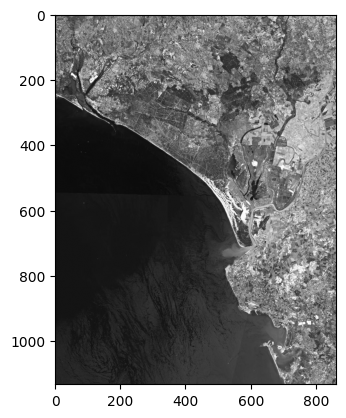

In [34]:
img = cv.imread("primeraImagen.jpeg")
imgray = cv. cvtColor(img, cv.COLOR_BGR2GRAY)
plt.imshow(imgray, cmap='gray')
plt.show()
ret, thresh = cv.threshold(imgray, 220,255,0)
contours, hierarchy = cv.findContours(thresh, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

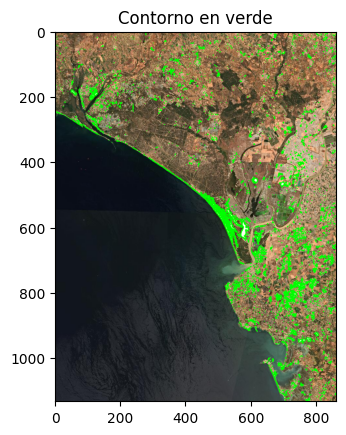

True

In [40]:
#TAREA 8
img_contornos = img.copy()
cv.drawContours(img_contornos, contours, -1, (0, 255, 0), 2)
plt.imshow(cv.cvtColor(img_contornos, cv.COLOR_BGR2RGB))
plt.title("Contorno en verde")
plt.show()

cv.imwrite(str(Path.home() / "mystorage/práctica1/imagen_contorno_verde.jpeg"), img_contornos)

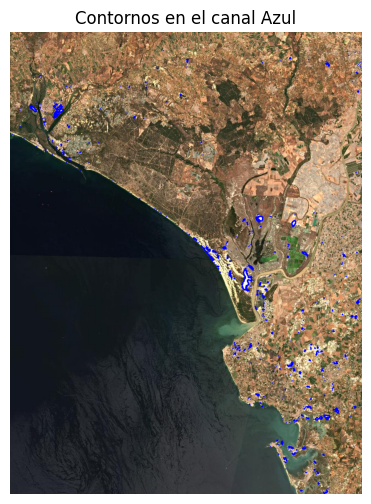

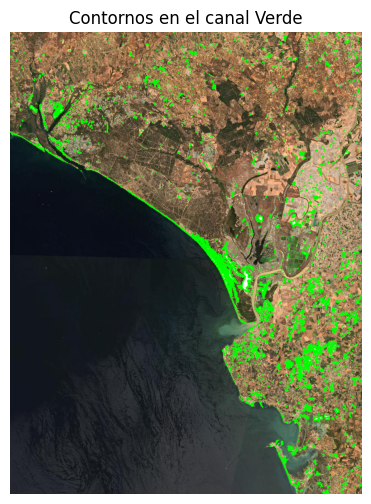

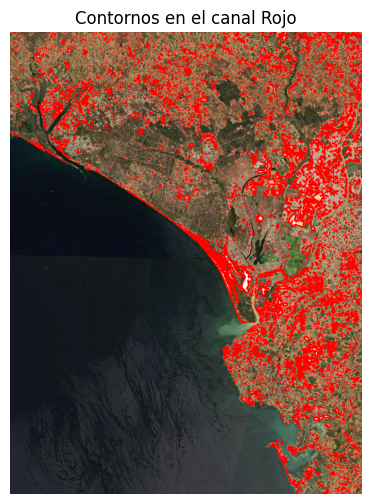

In [41]:
#TAREA9
b, g, r = cv.split(img)
canales = [b, g, r]
nombres = ["Azul", "Verde", "Rojo"]
colores = [(255, 0, 0), (0, 255, 0), (0, 0, 255)]

for canal, nombre, color in zip(canales, nombres, colores):
    _, binario = cv.threshold(canal, 220, 255, 0)
    contornos, _ = cv.findContours(binario, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
    img_contornos = img.copy()
    cv.drawContours(img_contornos, contornos, -1, color, 2)

    plt.figure(figsize=(6, 6))
    plt.imshow(cv.cvtColor(img_contornos, cv.COLOR_BGR2RGB))
    plt.title(f"Contornos en el canal {nombre}")
    plt.axis("off")
    plt.show()